# TP de statistique descriptive : Diabète à Kinshasa
Jeu de données : `Diabete_Kinshasa.xlsx` (données **synthétiques**, non représentatives de la population réelle de Kinshasa).

**Plan**
- Question 1 : exploration et préparation des données
- Question 2 : analyse statistique descriptive (statistiques, histogrammes, nuages de points, corrélations)

In [1]:
# 0. Imports et réglages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [3]:
# 1. Chargement du fichier Excel (feuille "Donnees")
# Dans Colab : cliquez sur "Choisir les fichiers" et sélectionnez Diabete_Kinshasa.xlsx
#from google.colab import files
#up = files.upload()
#chemin = list(up.keys())[0]

# Alternative avec Google Drive :
# from google.colab import drive; drive.mount('/content/drive')
# chemin = '/content/drive/MyDrive/Diabete_Kinshasa.xlsx'

df = pd.read_excel("Diabete_Kinshasa.xlsx")
df.head()

,ID_patient,Commune,Sexe,Age_ans,Type_diabete,Duree_diabete_ans,IMC_kg_m2,Tour_taille_cm,Glycemie_jeun_mg_dL,HbA1c_pct,Pression_systolique_mmHg,Pression_diastolique_mmHg,Cholesterol_total_mg_dL,HDL_mg_dL,Triglycerides_mg_dL,Activite_physique_min_sem,DFG_mL_min_1_73m2,Traitement
0,DIA-0001,Kasa-Vubu,M,47,Type 1,6.40,29.40,108.60,159.00,7.50,128.00,70.00,179.00,51.00,129.00,287.00,106.00,Insuline
1,DIA-0002,Kimbanseke,F,55,Type 2,20.40,31.20,87.70,233.00,8.60,153.00,78.00,176.00,48.00,173.00,25.00,110.00,Antidiabetiques oraux
2,DIA-0003,Kalamu,F,61,Type 2,9.60,26.90,82.60,166.00,9.60,120.00,75.00,190.00,49.00,106.00,141.00,82.00,Insuline
3,DIA-0004,Kasa-Vubu,M,28,Type 2,6.70,23.70,89.30,114.00,6.80,89.00,65.00,200.00,48.00,121.00,48.00,140.00,Antidiabetiques oraux
4,DIA-0005,Bandalungwa,M,63,Type 2,5.40,21.90,78.80,212.00,8.10,123.00,88.00,183.00,51.00,99.00,171.00,112.00,Insuline


## QUESTION 1 : Exploration et préparation des données
### 1.0 Présentation du jeu de données

In [4]:
n_obs, n_var = df.shape
print(f"Nombre d'observations (patients) : {n_obs}")
print(f"Nombre de variables              : {n_var}")
print()
df.info()

Nombre d'observations (patients) : 1200
Nombre de variables              : 18

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID_patient                 1200 non-null   object 
 1   Commune                    1200 non-null   object 
 2   Sexe                       1200 non-null   object 
 3   Age_ans                    1200 non-null   int64  
 4   Type_diabete               1200 non-null   object 
 5   Duree_diabete_ans          1177 non-null   float64
 6   IMC_kg_m2                  1182 non-null   float64
 7   Tour_taille_cm             1182 non-null   float64
 8   Glycemie_jeun_mg_dL        1165 non-null   float64
 9   HbA1c_pct                  1181 non-null   float64
 10  Pression_systolique_mmHg   1188 non-null   float64
 11  Pression_diastolique_mmHg  1182 non-null   float64
 12  Cholesterol_total_mg_dL  

In [5]:
# Nature de chaque variable
identifiant = ["ID_patient"]
qualitatives = ["Commune", "Sexe", "Type_diabete", "Traitement"]
quantitatives = [c for c in df.columns if c not in identifiant + qualitatives]

nature = []
for c in df.columns:
    if c in identifiant:
        nat, sous = "Identifiant (non analysé)", "-"
    elif c in qualitatives:
        nat, sous = "Qualitative", "Nominale"
    else:
        nat = "Quantitative"
        sous = "Discrète" if c == "Age_ans" else "Continue"
    nature.append({"Variable": c, "Type pandas": str(df[c].dtype), "Nature": nat,
                   "Sous-type": sous, "Modalités / valeurs distinctes": df[c].nunique()})
tableau_nature = pd.DataFrame(nature)
display(tableau_nature)
print("\nVariables quantitatives :", len(quantitatives))
print("Variables qualitatives  :", len(qualitatives))

,Variable,Type pandas,Nature,Sous-type,Modalités / valeurs distinctes
0,ID_patient,object,Identifiant (non analysé),-,1200
1,Commune,object,Qualitative,Nominale,14
2,Sexe,object,Qualitative,Nominale,2
3,Age_ans,int64,Quantitative,Discrète,68
4,Type_diabete,object,Qualitative,Nominale,2
5,Duree_diabete_ans,float64,Quantitative,Continue,190
6,IMC_kg_m2,float64,Quantitative,Continue,183
7,Tour_taille_cm,float64,Quantitative,Continue,396
8,Glycemie_jeun_mg_dL,float64,Quantitative,Continue,173
9,HbA1c_pct,float64,Quantitative,Continue,55



Variables quantitatives : 13
Variables qualitatives  : 4


In [6]:
# Répartition des variables qualitatives
for c in qualitatives:
    print(f"--- {c} ---")
    print(df[c].value_counts().to_frame("effectif").assign(pourcentage=lambda t: 100*t.effectif/len(df)))
    print()

--- Commune ---
              effectif  pourcentage
Commune                            
Bandalungwa         97         8.08
Masina              95         7.92
Limete              94         7.83
Kalamu              93         7.75
Selembao            92         7.67
Lemba               91         7.58
N'Djili             89         7.42
Gombe               88         7.33
Matete              85         7.08
Kintambo            82         6.83
Ngaliema            78         6.50
Mont-Ngafula        77         6.42
Kimbanseke          74         6.17
Kasa-Vubu           65         5.42

--- Sexe ---
      effectif  pourcentage
Sexe                       
F          674        56.17
M          526        43.83

--- Type_diabete ---
              effectif  pourcentage
Type_diabete                       
Type 2            1086        90.50
Type 1             114         9.50

--- Traitement ---
                             effectif  pourcentage
Traitement                                   

### 1.1 Valeurs manquantes, doublons et valeurs aberrantes

In [7]:
# a) Valeurs manquantes
manq = df.isna().sum().to_frame("n_manquantes")
manq["pourcentage"] = 100 * manq["n_manquantes"] / len(df)
manq = manq[manq.n_manquantes > 0].sort_values("n_manquantes", ascending=False)
display(manq)
print(f"Lignes avec au moins une valeur manquante : {df.isna().any(axis=1).sum()} ({100*df.isna().any(axis=1).mean():.1f} %)")
print(f"Total de cellules manquantes : {df.isna().sum().sum()}")

,n_manquantes,pourcentage
Glycemie_jeun_mg_dL,35,2.92
Cholesterol_total_mg_dL,26,2.17
Triglycerides_mg_dL,25,2.08
DFG_mL_min_1_73m2,25,2.08
Duree_diabete_ans,23,1.92
Activite_physique_min_sem,20,1.67
HbA1c_pct,19,1.58
HDL_mg_dL,19,1.58
Tour_taille_cm,18,1.50
IMC_kg_m2,18,1.50


Lignes avec au moins une valeur manquante : 238 (19.8 %)
Total de cellules manquantes : 258


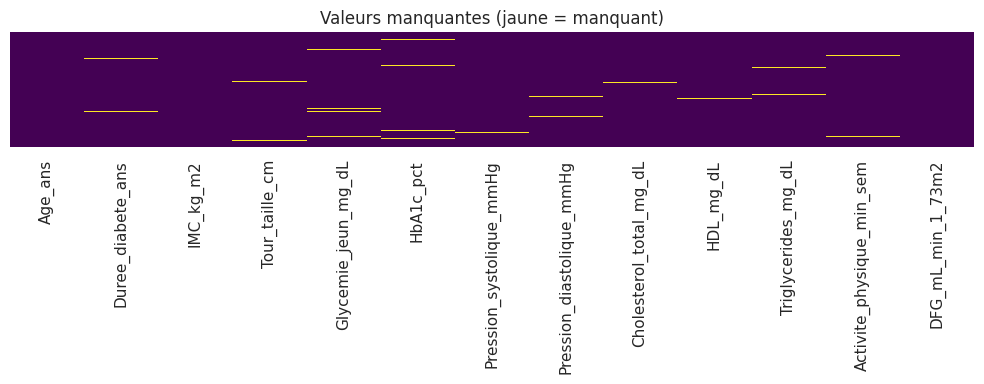

In [8]:
# Visualisation des valeurs manquantes
plt.figure(figsize=(10, 4))
sns.heatmap(df[quantitatives].isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Valeurs manquantes (jaune = manquant)")
plt.tight_layout(); plt.show()

In [9]:
# b) Doublons
print("Lignes entièrement dupliquées :", df.duplicated().sum())
print("Identifiants patients dupliqués :", df["ID_patient"].duplicated().sum())
print("Doublons en ignorant l'identifiant :", df.drop(columns="ID_patient").duplicated().sum())

Lignes entièrement dupliquées : 0
Identifiants patients dupliqués : 0
Doublons en ignorant l'identifiant : 0


In [10]:
# c) Valeurs aberrantes : règle de Tukey (1,5 x IQR) + boîtes à moustaches
def bornes_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

res = []
for c in quantitatives:
    bi, bs = bornes_iqr(df[c].dropna())
    n_out = ((df[c] < bi) | (df[c] > bs)).sum()
    res.append({"Variable": c, "Borne inf.": bi, "Borne sup.": bs,
                "Min observé": df[c].min(), "Max observé": df[c].max(),
                "n_aberrantes": n_out, "% aberrantes": 100 * n_out / df[c].notna().sum()})
table_out = pd.DataFrame(res).set_index("Variable")
display(table_out)

,Borne inf.,Borne sup.,Min observé,Max observé,n_aberrantes,% aberrantes
Variable,,,,,,
Age_ans,8.00,88.00,18.00,85.00,0,0.00
Duree_diabete_ans,-5.15,17.65,0.10,30.70,33,2.80
IMC_kg_m2,15.90,37.50,17.00,38.10,5,0.42
Tour_taille_cm,64.19,114.89,61.40,125.00,19,1.61
Glycemie_jeun_mg_dL,85.50,273.50,68.00,281.00,7,0.60
HbA1c_pct,5.55,10.75,5.40,11.20,4,0.34
Pression_systolique_mmHg,82.00,154.00,88.00,156.00,2,0.17
Pression_diastolique_mmHg,49.00,97.00,52.00,100.00,2,0.17
Cholesterol_total_mg_dL,102.00,262.00,100.00,271.00,10,0.85


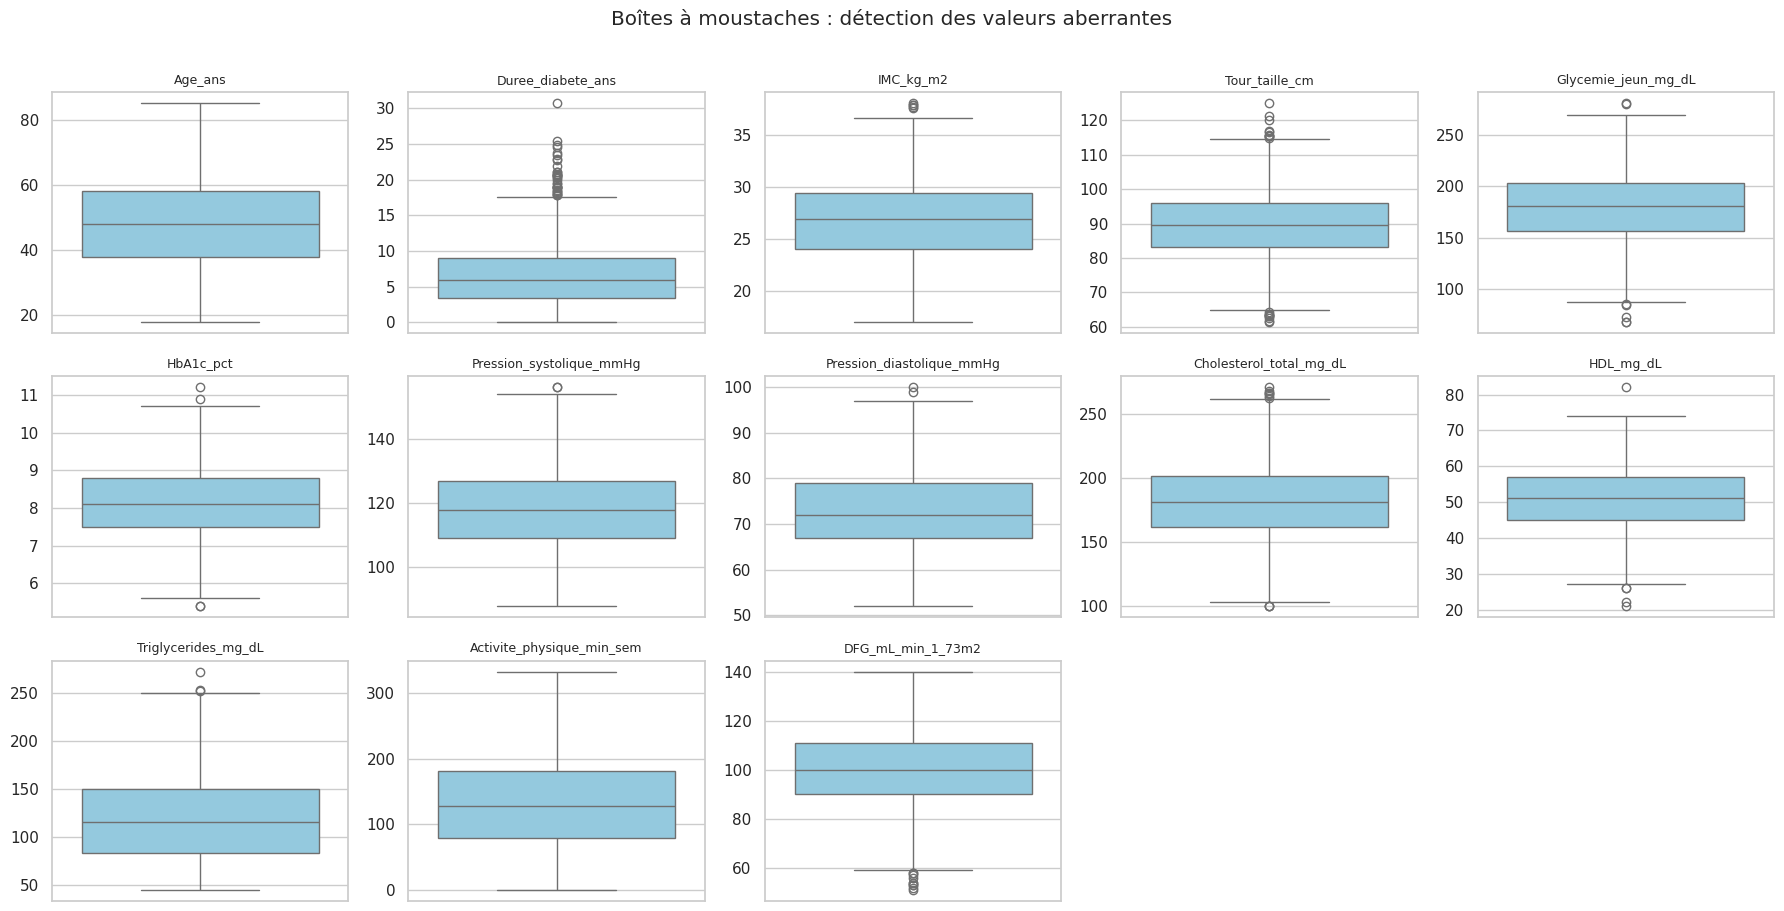

In [11]:
fig, axes = plt.subplots(3, 5, figsize=(18, 9))
for ax, c in zip(axes.ravel(), quantitatives):
    sns.boxplot(y=df[c], ax=ax, color="skyblue")
    ax.set_title(c, fontsize=9); ax.set_ylabel("")
for ax in axes.ravel()[len(quantitatives):]:
    ax.axis("off")
plt.suptitle("Boîtes à moustaches : détection des valeurs aberrantes", y=1.01)
plt.tight_layout(); plt.show()

In [12]:
# Vérification de la plausibilité clinique (valeurs impossibles ?)
verif = {
    "Age_ans": (0, 120), "Duree_diabete_ans": (0, 70), "IMC_kg_m2": (10, 70),
    "Tour_taille_cm": (40, 200), "Glycemie_jeun_mg_dL": (20, 600), "HbA1c_pct": (3, 20),
    "Pression_systolique_mmHg": (60, 260), "Pression_diastolique_mmHg": (30, 150),
    "Cholesterol_total_mg_dL": (50, 500), "HDL_mg_dL": (10, 150),
    "Triglycerides_mg_dL": (20, 1000), "Activite_physique_min_sem": (0, 2000),
    "DFG_mL_min_1_73m2": (5, 200),
}
impossibles = {c: int(((df[c] < lo) | (df[c] > hi)).sum()) for c, (lo, hi) in verif.items()}
print("Valeurs physiologiquement impossibles par variable :", impossibles)
print("Total :", sum(impossibles.values()))

# Cohérence : la pression systolique doit dépasser la diastolique
incoh = (df["Pression_systolique_mmHg"] <= df["Pression_diastolique_mmHg"]).sum()
print("Pression systolique <= diastolique :", incoh)

Valeurs physiologiquement impossibles par variable : {'Age_ans': 0, 'Duree_diabete_ans': 0, 'IMC_kg_m2': 0, 'Tour_taille_cm': 0, 'Glycemie_jeun_mg_dL': 0, 'HbA1c_pct': 0, 'Pression_systolique_mmHg': 0, 'Pression_diastolique_mmHg': 0, 'Cholesterol_total_mg_dL': 0, 'HDL_mg_dL': 0, 'Triglycerides_mg_dL': 0, 'Activite_physique_min_sem': 0, 'DFG_mL_min_1_73m2': 0}
Total : 0
Pression systolique <= diastolique : 1


### 1.2 Nettoyage et justification des choix

**Choix effectués (à adapter selon les résultats ci-dessus) :**
1. **Identifiant** : `ID_patient` est conservé comme clé mais exclu de toute analyse statistique.
2. **Doublons** : aucun doublon détecté, donc aucune ligne supprimée.
3. **Valeurs manquantes** : elles représentent moins de 3 % par variable et sont dispersées (pas de patient très incomplet). Supprimer les lignes concernées ferait perdre beaucoup d'observations. On impute donc par la **médiane**, robuste aux valeurs extrêmes, calculée **par type de diabète** (Type 1 / Type 2) car les profils diffèrent. Les données originales sont conservées dans `df` ; la version nettoyée est `df_clean`.
4. **Valeurs aberrantes** : les valeurs signalées par la règle de Tukey sont **conservées** si elles sont cliniquement plausibles (ex. durée de diabète de 30 ans, tour de taille élevé, glycémie très haute) : ce sont des cas réels de patients, pas des erreurs de saisie. Seules des valeurs impossibles seraient corrigées ou supprimées (aucune ici).

In [13]:
df_clean = df.copy()

# Imputation par la médiane du groupe (Type_diabete)
for c in quantitatives:
    df_clean[c] = df_clean[c].fillna(df_clean.groupby("Type_diabete")[c].transform("median"))
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())   # filet de sécurité

# Nettoyage des libellés qualitatifs (espaces parasites)
for c in qualitatives:
    df_clean[c] = df_clean[c].astype(str).str.strip()

# Suppression d'éventuels doublons
avant = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Lignes supprimées (doublons) : {avant - len(df_clean)}")
print("Valeurs manquantes restantes :", int(df_clean.isna().sum().sum()))
print("Dimensions après nettoyage   :", df_clean.shape)

Lignes supprimées (doublons) : 0
Valeurs manquantes restantes : 0
Dimensions après nettoyage   : (1200, 18)


In [14]:
# Contrôle : l'imputation ne change presque pas les moyennes
comp = pd.DataFrame({"moyenne avant": df[quantitatives].mean(),
                     "moyenne après": df_clean[quantitatives].mean(),
                     "écart-type avant": df[quantitatives].std(),
                     "écart-type après": df_clean[quantitatives].std()})
display(comp)

,moyenne avant,moyenne après,écart-type avant,écart-type après
Age_ans,48.20,48.20,14.58,14.58
Duree_diabete_ans,6.71,6.69,4.44,4.40
IMC_kg_m2,26.72,26.73,3.94,3.91
Tour_taille_cm,89.69,89.68,9.94,9.87
Glycemie_jeun_mg_dL,179.41,179.45,34.89,34.38
HbA1c_pct,8.12,8.12,0.95,0.94
Pression_systolique_mmHg,117.66,117.67,13.50,13.43
Pression_diastolique_mmHg,72.68,72.68,8.89,8.82
Cholesterol_total_mg_dL,182.05,182.04,31.14,30.80
HDL_mg_dL,50.81,50.81,8.95,8.88


## QUESTION 2 : Analyse statistique descriptive
### 2.1 Statistiques descriptives des variables quantitatives

In [ ]:
stats = pd.DataFrame({
    "Effectif": df_clean[quantitatives].count(),
    "Moyenne": df_clean[quantitatives].mean(),
    "Médiane": df_clean[quantitatives].median(),
    "Minimum": df_clean[quantitatives].min(),
    "Maximum": df_clean[quantitatives].max(),
    "Variance": df_clean[quantitatives].var(ddof=1),      # variance d'échantillon
    "Écart-type": df_clean[quantitatives].std(ddof=1),
})
stats["Coef. de variation (%)"] = 100 * stats["Écart-type"] / stats["Moyenne"]
stats["Asymétrie"] = df_clean[quantitatives].skew()
display(stats.round(2))

# Export éventuel
# stats.round(2).to_excel("statistiques_descriptives.xlsx")

In [15]:
# Statistiques selon le type de diabète (complément utile)
display(df_clean.groupby("Type_diabete")[["Age_ans", "Duree_diabete_ans", "IMC_kg_m2",
        "Glycemie_jeun_mg_dL", "HbA1c_pct", "DFG_mL_min_1_73m2"]].agg(["mean", "median", "std"]).round(2))

Age_ans              Duree_diabete_ans             IMC_kg_m2  \
                mean median   std              mean median  std      mean   
Type_diabete                                                                
Type 1         47.95  48.00 15.47              5.81   5.20 3.50     26.64   
Type 2         48.23  48.50 14.49              6.78   5.90 4.48     26.73   

                         Glycemie_jeun_mg_dL              HbA1c_pct         \
             median  std                mean median   std      mean median   
Type_diabete                                                                 
Type 1        26.90 3.85              178.09 178.00 32.21      8.03   8.10   
Type 2        26.90 3.92              179.59 181.00 34.61      8.13   8.10   

                  DFG_mL_min_1_73m2               
              std              mean median   std  
Type_diabete                                      
Type 1       0.91            100.35 101.00 17.17  
Type 2       0.95             99.81 100.00 16.34

### 2.2 Histogrammes (distribution de variables quantitatives)

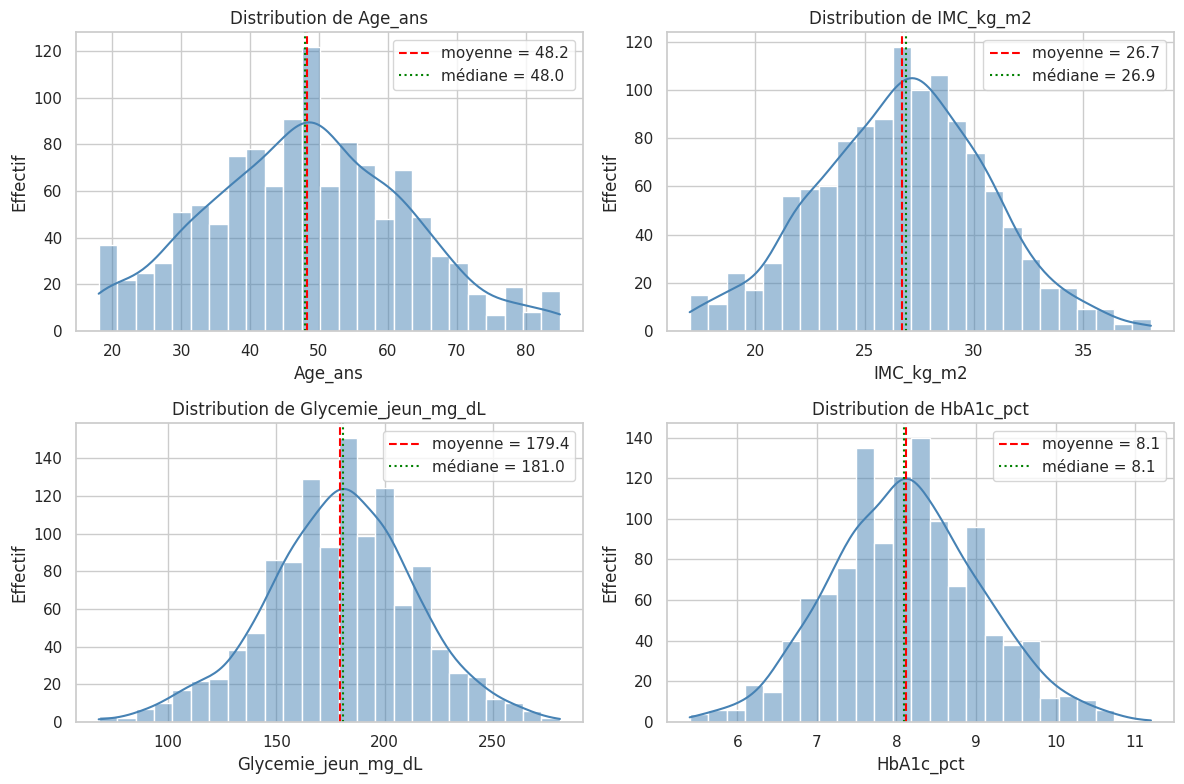

In [16]:
vars_hist = ["Age_ans", "IMC_kg_m2", "Glycemie_jeun_mg_dL", "HbA1c_pct"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.ravel(), vars_hist):
    sns.histplot(df_clean[c], bins=25, kde=True, ax=ax, color="steelblue")
    ax.axvline(df_clean[c].mean(), color="red", ls="--", label=f"moyenne = {df_clean[c].mean():.1f}")
    ax.axvline(df_clean[c].median(), color="green", ls=":", label=f"médiane = {df_clean[c].median():.1f}")
    ax.set_title(f"Distribution de {c}"); ax.set_ylabel("Effectif"); ax.legend()
plt.tight_layout(); plt.show()

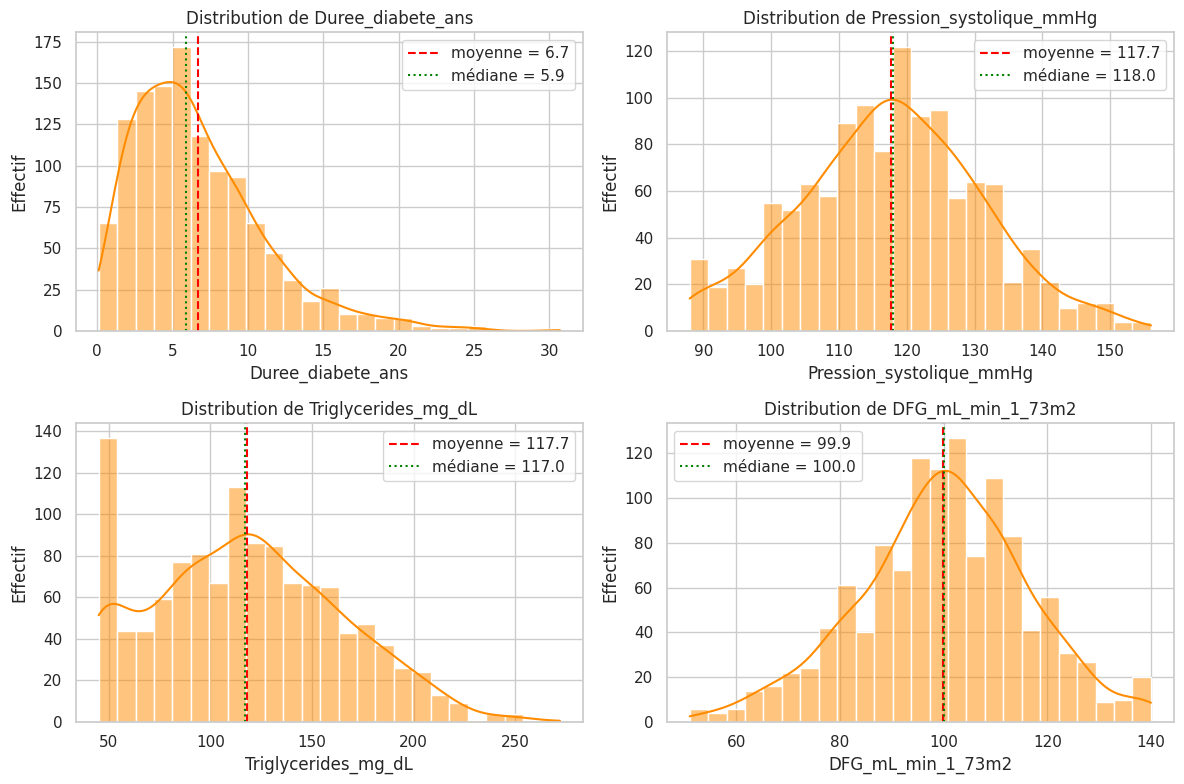

In [17]:
# Histogrammes complémentaires
vars_hist2 = ["Duree_diabete_ans", "Pression_systolique_mmHg", "Triglycerides_mg_dL", "DFG_mL_min_1_73m2"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.ravel(), vars_hist2):
    sns.histplot(df_clean[c], bins=25, kde=True, ax=ax, color="darkorange")
    ax.axvline(df_clean[c].mean(), color="red", ls="--", label=f"moyenne = {df_clean[c].mean():.1f}")
    ax.axvline(df_clean[c].median(), color="green", ls=":", label=f"médiane = {df_clean[c].median():.1f}")
    ax.set_title(f"Distribution de {c}"); ax.set_ylabel("Effectif"); ax.legend()
plt.tight_layout(); plt.show()

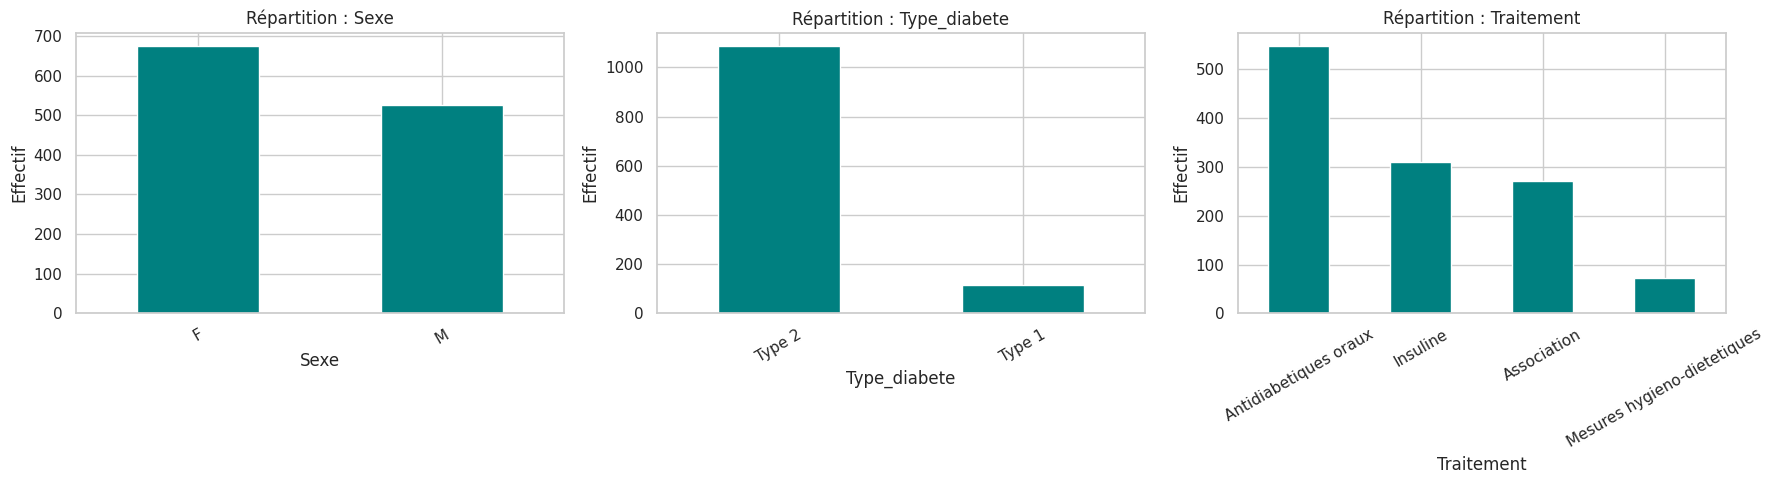

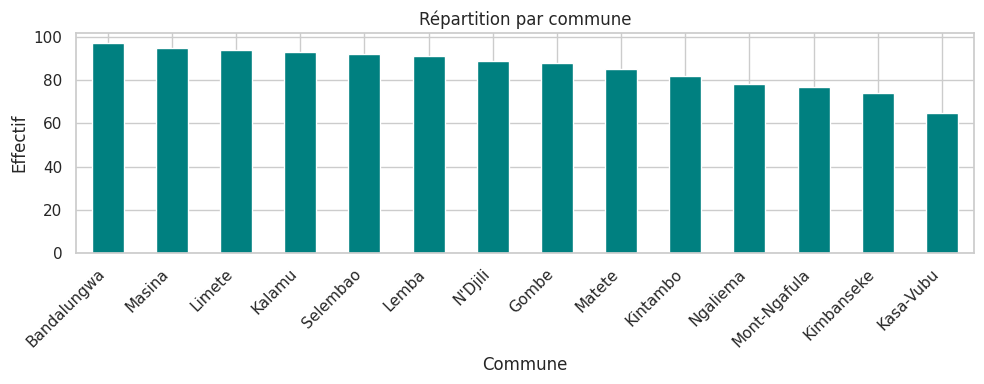

In [18]:
# Diagrammes en barres des variables qualitatives
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, c in zip(axes, ["Sexe", "Type_diabete", "Traitement"]):
    df_clean[c].value_counts().plot(kind="bar", ax=ax, color="teal")
    ax.set_title(f"Répartition : {c}"); ax.set_ylabel("Effectif"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 4))
df_clean["Commune"].value_counts().plot(kind="bar", color="teal")
plt.title("Répartition par commune"); plt.ylabel("Effectif"); plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

### 2.3 Nuages de points (relations entre variables quantitatives)

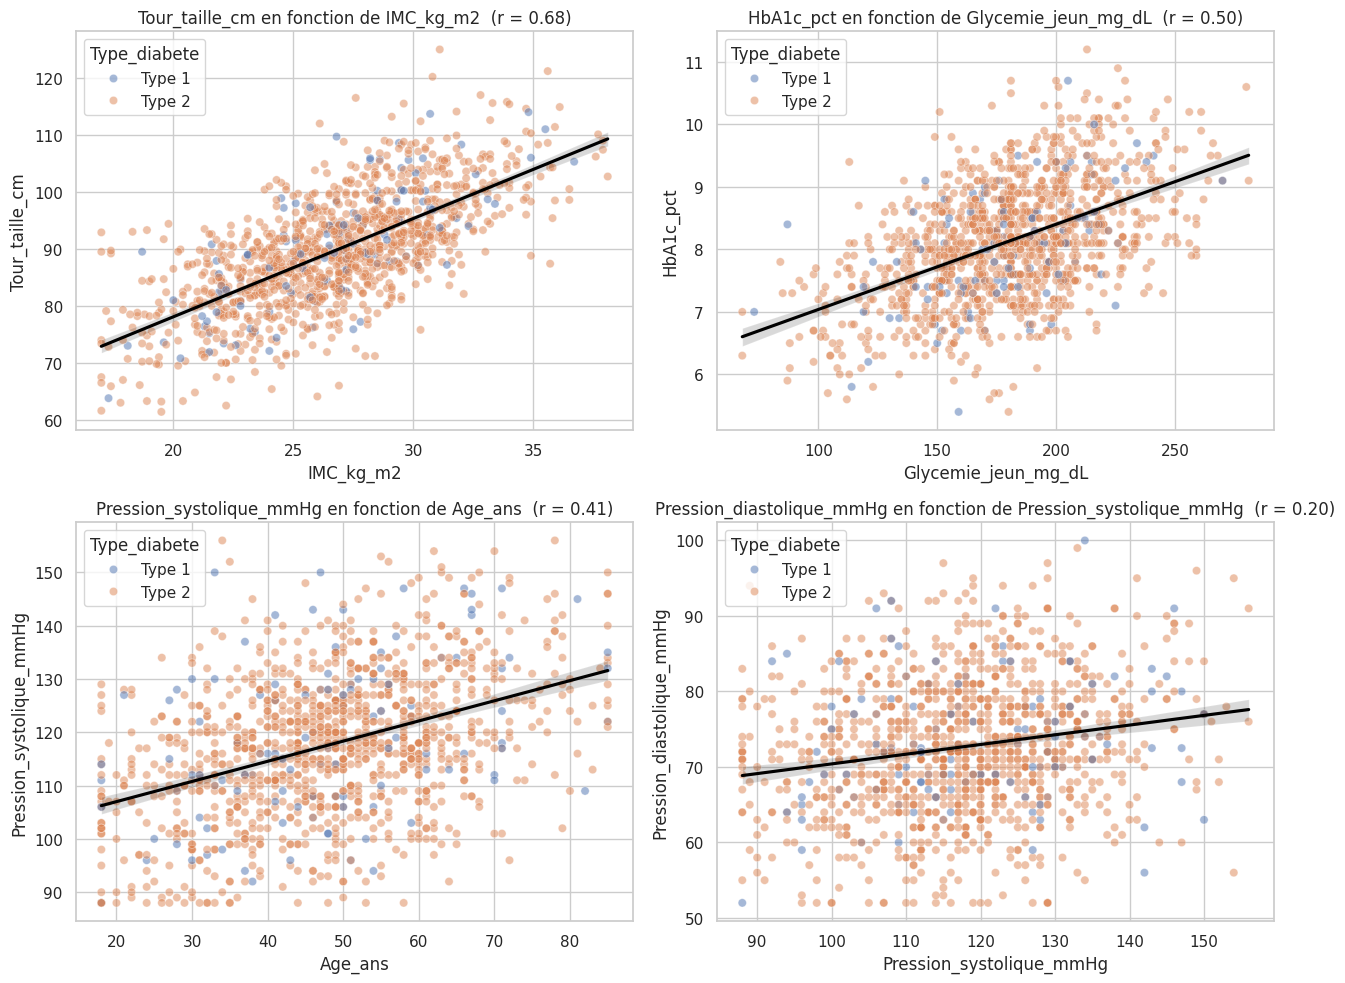

In [19]:
paires = [("IMC_kg_m2", "Tour_taille_cm"),
          ("Glycemie_jeun_mg_dL", "HbA1c_pct"),
          ("Age_ans", "Pression_systolique_mmHg"),
          ("Pression_systolique_mmHg", "Pression_diastolique_mmHg")]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (x, y) in zip(axes.ravel(), paires):
    sns.scatterplot(data=df_clean, x=x, y=y, hue="Type_diabete", alpha=0.5, ax=ax)
    sns.regplot(data=df_clean, x=x, y=y, scatter=False, color="black", ax=ax)   # droite de régression
    r = df_clean[x].corr(df_clean[y])
    ax.set_title(f"{y} en fonction de {x}  (r = {r:.2f})")
plt.tight_layout(); plt.show()

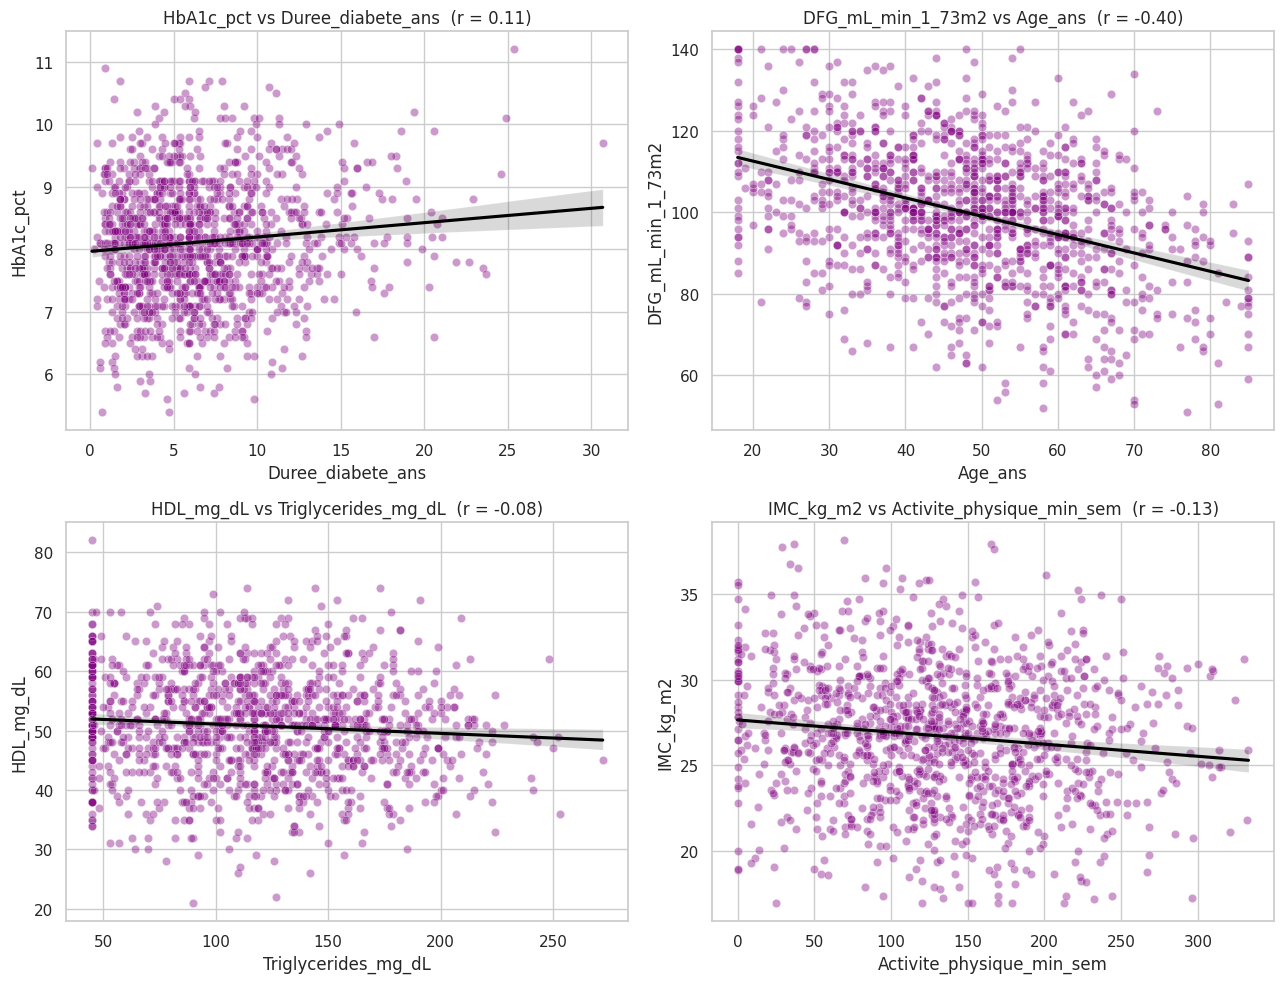

In [20]:
# Autres nuages utiles
paires2 = [("Duree_diabete_ans", "HbA1c_pct"), ("Age_ans", "DFG_mL_min_1_73m2"),
           ("Triglycerides_mg_dL", "HDL_mg_dL"), ("Activite_physique_min_sem", "IMC_kg_m2")]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (x, y) in zip(axes.ravel(), paires2):
    sns.scatterplot(data=df_clean, x=x, y=y, alpha=0.4, ax=ax, color="purple")
    sns.regplot(data=df_clean, x=x, y=y, scatter=False, color="black", ax=ax)
    ax.set_title(f"{y} vs {x}  (r = {df_clean[x].corr(df_clean[y]):.2f})")
plt.tight_layout(); plt.show()

### 2.4 Matrice de corrélation (Pearson)

,Age_ans,Duree_diabete_ans,IMC_kg_m2,Tour_taille_cm,Glycemie_jeun_mg_dL,HbA1c_pct,Pression_systolique_mmHg,Pression_diastolique_mmHg,Cholesterol_total_mg_dL,HDL_mg_dL,Triglycerides_mg_dL,Activite_physique_min_sem,DFG_mL_min_1_73m2
Age_ans,1.00,0.06,0.10,0.06,-0.02,0.04,0.41,0.45,-0.01,0.01,0.02,0.00,-0.40
Duree_diabete_ans,0.06,1.00,0.01,-0.00,0.07,0.11,0.05,0.06,-0.04,-0.05,-0.02,-0.00,-0.21
IMC_kg_m2,0.10,0.01,1.00,0.68,0.01,-0.02,0.21,0.17,0.26,-0.27,0.18,-0.13,-0.06
Tour_taille_cm,0.06,-0.00,0.68,1.00,0.01,-0.02,0.12,0.14,0.17,-0.25,0.10,-0.08,-0.03
Glycemie_jeun_mg_dL,-0.02,0.07,0.01,0.01,1.00,0.50,-0.00,-0.02,0.09,0.01,0.11,-0.04,-0.07
HbA1c_pct,0.04,0.11,-0.02,-0.02,0.50,1.00,0.01,-0.02,0.11,-0.01,0.22,-0.01,-0.11
Pression_systolique_mmHg,0.41,0.05,0.21,0.12,-0.00,0.01,1.00,0.20,0.01,-0.02,0.02,-0.05,-0.19
Pression_diastolique_mmHg,0.45,0.06,0.17,0.14,-0.02,-0.02,0.20,1.00,0.01,0.01,0.01,-0.02,-0.17
Cholesterol_total_mg_dL,-0.01,-0.04,0.26,0.17,0.09,0.11,0.01,0.01,1.00,-0.07,0.13,-0.08,-0.05
HDL_mg_dL,0.01,-0.05,-0.27,-0.25,0.01,-0.01,-0.02,0.01,-0.07,1.00,-0.08,0.04,0.00


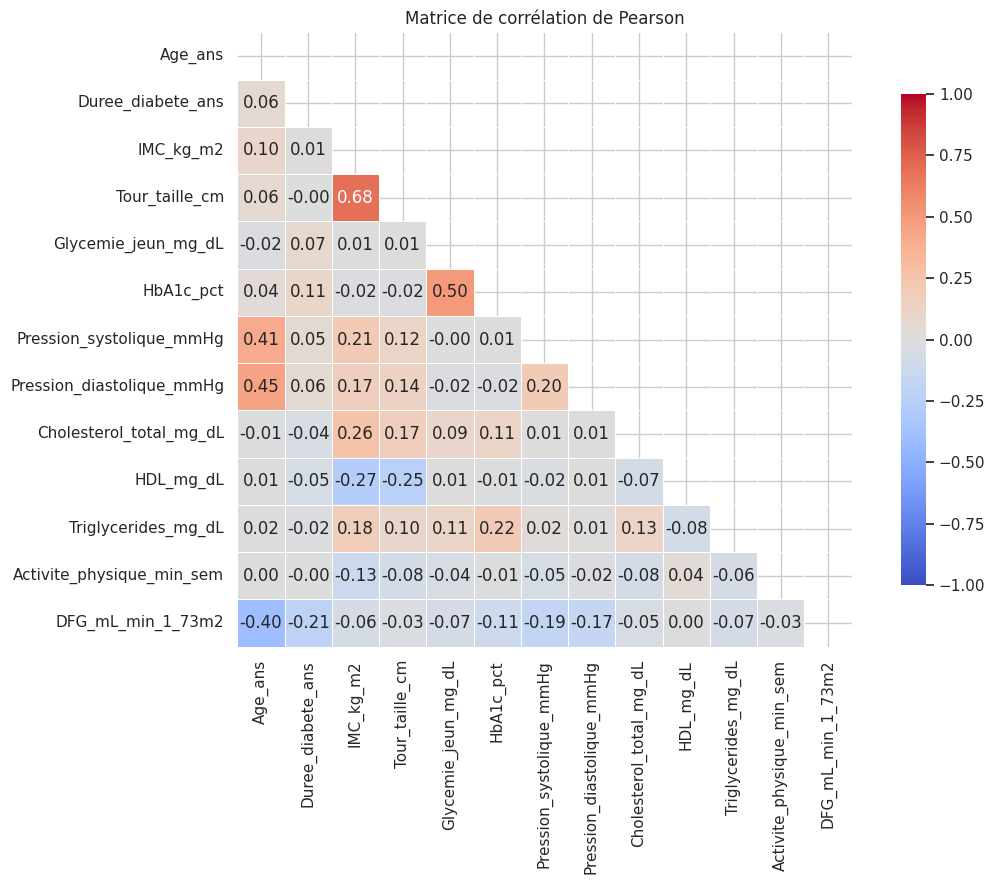

In [21]:
corr = df_clean[quantitatives].corr(method="pearson")
display(corr.round(2))

plt.figure(figsize=(12, 9))
masque = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=masque, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Matrice de corrélation de Pearson")
plt.tight_layout(); plt.show()

In [22]:
# Principales corrélations, classées par force
paires_corr = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
                   .stack().rename("r").reset_index())
paires_corr.columns = ["Variable 1", "Variable 2", "r"]
paires_corr["|r|"] = paires_corr["r"].abs()
paires_corr = paires_corr.sort_values("|r|", ascending=False)

def force(a):
    return "forte" if a >= 0.7 else "modérée" if a >= 0.4 else "faible" if a >= 0.2 else "négligeable"
paires_corr["Force"] = paires_corr["|r|"].apply(force)
paires_corr["Sens"] = np.where(paires_corr["r"] > 0, "positif", "négatif")

print("10 corrélations les plus fortes :")
display(paires_corr.head(10).round(3))
print("Corrélations avec |r| >= 0,2 :", (paires_corr["|r|"] >= 0.2).sum(), "sur", len(paires_corr))

10 corrélations les plus fortes :


,Variable 1,Variable 2,r,|r|,Force,Sens
23,IMC_kg_m2,Tour_taille_cm,0.68,0.68,modérée,positif
42,Glycemie_jeun_mg_dL,HbA1c_pct,0.50,0.50,modérée,positif
6,Age_ans,Pression_diastolique_mmHg,0.45,0.45,modérée,positif
5,Age_ans,Pression_systolique_mmHg,0.41,0.41,modérée,positif
11,Age_ans,DFG_mL_min_1_73m2,-0.40,0.40,modérée,négatif
29,IMC_kg_m2,HDL_mg_dL,-0.27,0.27,faible,négatif
28,IMC_kg_m2,Cholesterol_total_mg_dL,0.26,0.26,faible,positif
38,Tour_taille_cm,HDL_mg_dL,-0.25,0.25,faible,négatif
54,HbA1c_pct,Triglycerides_mg_dL,0.22,0.22,faible,positif
22,Duree_diabete_ans,DFG_mL_min_1_73m2,-0.21,0.21,faible,négatif


Corrélations avec |r| >= 0,2 : 11 sur 78


In [23]:
# Significativité des corrélations les plus fortes
from scipy import stats as st
lignes = []
for _, row in paires_corr.head(10).iterrows():
    r, p = st.pearsonr(df_clean[row["Variable 1"]], df_clean[row["Variable 2"]])
    lignes.append({"Variable 1": row["Variable 1"], "Variable 2": row["Variable 2"], "r": r, "p-value": p})
display(pd.DataFrame(lignes).round(4))

,Variable 1,Variable 2,r,p-value
0,IMC_kg_m2,Tour_taille_cm,0.68,0.00
1,Glycemie_jeun_mg_dL,HbA1c_pct,0.50,0.00
2,Age_ans,Pression_diastolique_mmHg,0.45,0.00
3,Age_ans,Pression_systolique_mmHg,0.41,0.00
4,Age_ans,DFG_mL_min_1_73m2,-0.40,0.00
5,IMC_kg_m2,HDL_mg_dL,-0.27,0.00
6,IMC_kg_m2,Cholesterol_total_mg_dL,0.26,0.00
7,Tour_taille_cm,HDL_mg_dL,-0.25,0.00
8,HbA1c_pct,Triglycerides_mg_dL,0.22,0.00
9,Duree_diabete_ans,DFG_mL_min_1_73m2,-0.21,0.00


**Interprétation des principales relations** (à rédiger à partir des résultats affichés ci-dessus ; la cellule suivante génère un texte de départ) :
- Une corrélation proche de +1 ou -1 indique une relation linéaire forte ; proche de 0, pas de relation linéaire.
- Corrélation n'est pas causalité, et ces données sont synthétiques.

In [24]:
# Texte d'interprétation généré automatiquement (à relire et reformuler)
print("INTERPRÉTATION AUTOMATIQUE DES 6 RELATIONS PRINCIPALES\n")
for _, row in paires_corr.head(6).iterrows():
    sens = ("quand l'une augmente, l'autre tend à augmenter" if row["r"] > 0
            else "quand l'une augmente, l'autre tend à diminuer")
    print(f"- {row['Variable 1']} et {row['Variable 2']} : r = {row['r']:.2f} "
          f"(corrélation {row['Force']} {row['Sens']}) ; {sens}.")

INTERPRÉTATION AUTOMATIQUE DES 6 RELATIONS PRINCIPALES

- IMC_kg_m2 et Tour_taille_cm : r = 0.68 (corrélation modérée positif) ; quand l'une augmente, l'autre tend à augmenter.
- Glycemie_jeun_mg_dL et HbA1c_pct : r = 0.50 (corrélation modérée positif) ; quand l'une augmente, l'autre tend à augmenter.
- Age_ans et Pression_diastolique_mmHg : r = 0.45 (corrélation modérée positif) ; quand l'une augmente, l'autre tend à augmenter.
- Age_ans et Pression_systolique_mmHg : r = 0.41 (corrélation modérée positif) ; quand l'une augmente, l'autre tend à augmenter.
- Age_ans et DFG_mL_min_1_73m2 : r = -0.40 (corrélation modérée négatif) ; quand l'une augmente, l'autre tend à diminuer.
- IMC_kg_m2 et HDL_mg_dL : r = -0.27 (corrélation faible négatif) ; quand l'une augmente, l'autre tend à diminuer.


### 2.5 Description détaillée du jeu de données (synthèse chiffrée)

In [25]:
# Chiffres clés pour rédiger la description
print(f"Effectif : {len(df_clean)} patients, {df_clean.shape[1]} variables "
      f"({len(quantitatives)} quantitatives, {len(qualitatives)} qualitatives, 1 identifiant).")
print(f"Sexe : {df_clean['Sexe'].value_counts(normalize=True).mul(100).round(1).to_dict()} (%)")
print(f"Type de diabète : {df_clean['Type_diabete'].value_counts(normalize=True).mul(100).round(1).to_dict()} (%)")
print(f"Traitement : {df_clean['Traitement'].value_counts(normalize=True).mul(100).round(1).to_dict()} (%)")
print(f"Âge moyen : {df_clean['Age_ans'].mean():.1f} ans (min {df_clean['Age_ans'].min()}, max {df_clean['Age_ans'].max()})")
print(f"IMC moyen : {df_clean['IMC_kg_m2'].mean():.1f} kg/m²")

# Proportions cliniques utiles (seuils usuels)
print("\n--- Indicateurs cliniques ---")
print(f"HbA1c >= 7 % (contrôle insuffisant) : {(df_clean['HbA1c_pct'] >= 7).mean()*100:.1f} %")
print(f"Glycémie à jeun >= 126 mg/dL        : {(df_clean['Glycemie_jeun_mg_dL'] >= 126).mean()*100:.1f} %")
print(f"IMC >= 25 (surpoids ou obésité)     : {(df_clean['IMC_kg_m2'] >= 25).mean()*100:.1f} %")
print(f"IMC >= 30 (obésité)                 : {(df_clean['IMC_kg_m2'] >= 30).mean()*100:.1f} %")
print(f"Pression systolique >= 140 mmHg     : {(df_clean['Pression_systolique_mmHg'] >= 140).mean()*100:.1f} %")
print(f"DFG < 60 mL/min/1,73m²              : {(df_clean['DFG_mL_min_1_73m2'] < 60).mean()*100:.1f} %")
print(f"Activité physique < 150 min/sem     : {(df_clean['Activite_physique_min_sem'] < 150).mean()*100:.1f} %")

Effectif : 1200 patients, 18 variables (13 quantitatives, 4 qualitatives, 1 identifiant).
Sexe : {'F': 56.2, 'M': 43.8} (%)
Type de diabète : {'Type 2': 90.5, 'Type 1': 9.5} (%)
Traitement : {'Antidiabetiques oraux': 45.6, 'Insuline': 25.8, 'Association': 22.6, 'Mesures hygieno-dietetiques': 6.1} (%)
Âge moyen : 48.2 ans (min 18, max 85)
IMC moyen : 26.7 kg/m²

--- Indicateurs cliniques ---
HbA1c >= 7 % (contrôle insuffisant) : 89.4 %
Glycémie à jeun >= 126 mg/dL        : 93.5 %
IMC >= 25 (surpoids ou obésité)     : 68.2 %
IMC >= 30 (obésité)                 : 20.7 %
Pression systolique >= 140 mmHg     : 5.2 %
DFG < 60 mL/min/1,73m²              : 1.0 %
Activité physique < 150 min/sem     : 61.4 %


,Age_ans,IMC_kg_m2,HbA1c_pct,HDL_mg_dL
Sexe,,,,
F,47.92,26.66,8.10,53.29
M,48.56,26.81,8.15,47.64


,Age_ans,Duree_diabete_ans,HbA1c_pct,Glycemie_jeun_mg_dL
Traitement,,,,
Antidiabetiques oraux,47.91,6.87,8.12,177.28
Association,48.51,6.59,8.14,181.45
Insuline,48.66,6.49,8.14,180.78
Mesures hygieno-dietetiques,47.30,6.59,8.01,182.60


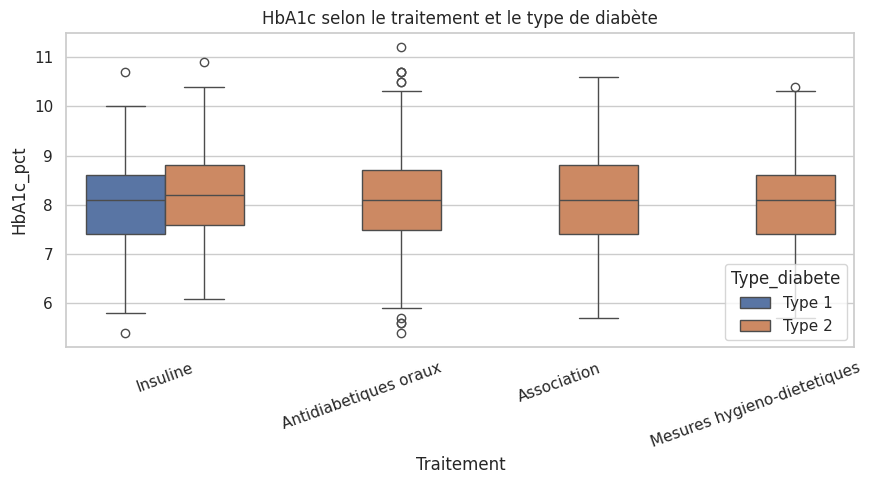

In [26]:
# Comparaisons entre groupes
display(df_clean.groupby("Sexe")[["Age_ans", "IMC_kg_m2", "HbA1c_pct", "HDL_mg_dL"]].mean().round(2))
display(df_clean.groupby("Traitement")[["Age_ans", "Duree_diabete_ans", "HbA1c_pct", "Glycemie_jeun_mg_dL"]].mean().round(2))

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x="Traitement", y="HbA1c_pct", hue="Type_diabete")
plt.xticks(rotation=20); plt.title("HbA1c selon le traitement et le type de diabète")
plt.tight_layout(); plt.show()

**Modèle de rédaction de la description détaillée** (compléter avec vos chiffres) :

Le jeu de données comprend *N* patients diabétiques résidant dans 14 communes de Kinshasa, décrits par 18 variables (1 identifiant, 4 qualitatives, 13 quantitatives). La cohorte est composée à *x* % de femmes et *y* % de patients de type 2. L'âge moyen est de *…* ans. Le contrôle glycémique est *…* (HbA1c moyenne = *…* %, *…* % des patients au-dessus de 7 %). L'IMC moyen est *…* ; *…* % des patients sont en surpoids ou obèses. Les distributions sont *(symétriques / asymétriques à droite)*, comme l'indiquent les coefficients d'asymétrie. Les corrélations les plus fortes sont *…* (glycémie à jeun et HbA1c, IMC et tour de taille, pression systolique et diastolique…), ce qui est cohérent avec la physiologie. Les autres variables sont peu corrélées entre elles. Limites : données simulées, non généralisables à la population réelle.